In [ ]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
#Pega o CSV puro do github e usa pra montar os dataframes ao inves de pegar do drive
url_listing="https://raw.githubusercontent.com/alvarolucio2007/Engenharia-de-Software/refs/heads/main/4Periodo/CienciaDeDados/ACE/Receipt%20Transactions0.csv"
df_vendas=pd.read_csv(url_listing)

url_transactions="https://raw.githubusercontent.com/alvarolucio2007/Engenharia-de-Software/refs/heads/main/4Periodo/CienciaDeDados/ACE/Service%20Listing0.csv"
df_transacoes=pd.read_csv(url_transactions)

#df_vendas = pd.read_csv('/content/drive/MyDrive/trabalho helo /Receipt Transactions0.csv')
#df_servicos = pd.read_csv('/content/drive/MyDrive/trabalho helo /Service Listing0.csv')

In [ ]:
df_vendas.head()

,Receipt,Date,Description,Client,Staff,Quantity,Amount,GST,PST
0,10,03/15/2018,Women's hair cut,KERT01,JJ,1,82.0,4.10,6.56
1,100,04/05/2018,Women's hair cut,COOM01,SINEAD,1,70.0,3.50,5.60
2,1000,06/09/2018,Consultation,PEDM01,JJ,1,0.0,0.00,0.00
3,1001,06/09/2018,Women's hair cut,BAIS01,KELLY,1,55.0,2.75,4.40
4,1003,06/09/2018,Women's hair cut,FRAL01,KELLY,1,65.0,3.25,5.20


In [ ]:
#df_servicos.head()

In [ ]:
df_vendas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1934 entries, 0 to 1933
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Receipt      1934 non-null   int64  
 1   Date         1934 non-null   object 
 2   Description  1931 non-null   object 
 3   Client       1934 non-null   object 
 4   Staff        1934 non-null   object 
 5   Quantity     1934 non-null   int64  
 6   Amount       1934 non-null   float64
 7   GST          1934 non-null   float64
 8   PST          1934 non-null   float64
dtypes: float64(3), int64(2), object(4)
memory usage: 136.1+ KB


In [ ]:
df_vendas['GST'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 1934 entries, 0 to 1933
Series name: GST
Non-Null Count  Dtype  
--------------  -----  
1934 non-null   float64
dtypes: float64(1)
memory usage: 15.2 KB


In [ ]:
df_vendas.drop(columns=['PST', 'GST'])
#Engracado que se der um drop dessas colunas no dataframe real, n tem mais linhas duplicadas abaixo (pra dar drop no real so colocar df_vendas=df_vendas.drop(...))

,Receipt,Date,Description,Client,Staff,Quantity,Amount
0,10,03/15/2018,Women's hair cut,KERT01,JJ,1,82.0
1,100,04/05/2018,Women's hair cut,COOM01,SINEAD,1,70.0
2,1000,06/09/2018,Consultation,PEDM01,JJ,1,0.0
3,1001,06/09/2018,Women's hair cut,BAIS01,KELLY,1,55.0
4,1003,06/09/2018,Women's hair cut,FRAL01,KELLY,1,65.0
...,...,...,...,...,...,...,...
1929,995,06/09/2018,Color touch up,LEAS01,JOANNE,1,50.0
1930,998,06/09/2018,Men's hair cut,CAND01,JJ,1,60.0
1931,998,06/09/2018,Men's camo color,CAND01,JJ,1,45.0
1932,999,06/09/2018,Color touch up,KOSI01,JOANNE,1,70.0


In [ ]:
df_vendas.isnull().sum()

,0
Receipt,0
Date,0
Description,3
Client,0
Staff,0
Quantity,0
Amount,0
GST,0
PST,0


In [ ]:
duplicatas = df_vendas[df_vendas.duplicated()]

duplicatas

,Receipt,Date,Description,Client,Staff,Quantity,Amount,GST,PST
25,1019,06/12/2018,Smart Bond,ALCV01,KELLY,1,25.0,1.25,2.0


In [ ]:
df_vendas.duplicated(subset=['Date'])
#Talvez deletar depois? Data pode ser duplicada de boa

,0
0,False
1,False
2,False
3,True
4,True
...,...
1929,True
1930,True
1931,True
1932,True


In [ ]:
df_vendas[df_vendas.duplicated(keep=False)]
#Estas sao as linhas duplicadas.

,Receipt,Date,Description,Client,Staff,Quantity,Amount,GST,PST
22,1019,06/12/2018,Smart Bond,ALCV01,KELLY,1,25.0,1.25,2.0
25,1019,06/12/2018,Smart Bond,ALCV01,KELLY,1,25.0,1.25,2.0


In [ ]:
df_vendas=df_vendas.drop_duplicates(keep='first')
df_vendas.duplicated().any()
#Nao ha mais linhas duplicadas

np.False_

In [ ]:
df_vendas
#Nao tem duplicatas, nao tem nulos ent so analise daq em diante

,Receipt,Date,Description,Client,Staff,Quantity,Amount,GST,PST
0,10,03/15/2018,Women's hair cut,KERT01,JJ,1,82.0,4.10,6.56
1,100,04/05/2018,Women's hair cut,COOM01,SINEAD,1,70.0,3.50,5.60
2,1000,06/09/2018,Consultation,PEDM01,JJ,1,0.0,0.00,0.00
3,1001,06/09/2018,Women's hair cut,BAIS01,KELLY,1,55.0,2.75,4.40
4,1003,06/09/2018,Women's hair cut,FRAL01,KELLY,1,65.0,3.25,5.20
...,...,...,...,...,...,...,...,...,...
1929,995,06/09/2018,Color touch up,LEAS01,JOANNE,1,50.0,2.50,4.00
1930,998,06/09/2018,Men's hair cut,CAND01,JJ,1,60.0,3.00,4.80
1931,998,06/09/2018,Men's camo color,CAND01,JJ,1,45.0,2.25,3.60
1932,999,06/09/2018,Color touch up,KOSI01,JOANNE,1,70.0,3.50,5.60


In [ ]:
df_vendas['Receipt'].duplicated().sum()
#497 recibos duplicados rpz


np.int64(497)

In [ ]:
df_vendas[df_vendas['Receipt'].duplicated(keep=False)].sort_values(by='Receipt')
#Mesmos clientes podem ter o mesmo numero do recibo portanto nao e problema

,Receipt,Date,Description,Client,Staff,Quantity,Amount,GST,PST
123,11,03/15/2018,Men's hair cut,SCHJ01,JJ,1,0.0,0.00,0.0
122,11,03/15/2018,Men's camo color,SCHJ01,JJ,1,0.0,0.00,0.0
124,11,03/15/2018,Consultation,SCHJ01,JJ,1,0.0,0.00,0.0
1409,58,03/28/2018,Men's camo color,CAND01,JJ,1,45.0,2.25,3.6
1408,58,03/28/2018,Men's hair cut,CAND01,JJ,1,40.0,2.00,3.2
...,...,...,...,...,...,...,...,...,...
925,1755,07/28/2018,Color touch up,IRWE01,JOANNE,1,70.0,3.50,5.6
929,1762,07/28/2018,accent lights,BURT01,JOANNE,1,45.0,2.25,3.6
930,1762,07/28/2018,Men's hair cut,BURT01,JJ,1,60.0,3.00,4.8
935,1766,07/28/2018,miscellaneous,BROS01,HOUSE,1,-50.0,-2.50,-4.0


<Axes: xlabel='Staff', ylabel='Amount'>

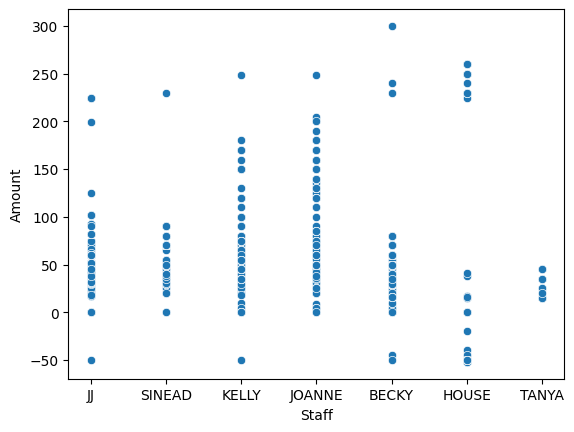

In [ ]:
sns.scatterplot(df_vendas,x='Staff',y='Amount')
#Da pra ver q tem valor menor q 0, acho que pode dar drop seguramente neles
#Tambem tem igual a 0 mas pode ser por promocao (faca uma pedicure e ganhe uma manicure por exemplo sla)

In [ ]:
df_vendas[df_vendas['Amount'] < 0]['Description'].unique()
#Nao parecem ser de estorno ou devolucao entao deixar positivo parece ser a melhor opcao

array(['miscellaneous', 'Shu cleansing oil sh400ml', 'Consultation'],
      dtype=object)

In [ ]:
df_vendas[df_vendas['Description'] == 'miscellaneous']
#Miscellaneous e sempre negativo, o restante nao


,Receipt,Date,Description,Client,Staff,Quantity,Amount,GST,PST
58,1042,06/14/2018,miscellaneous,WALK_IN,HOUSE,1,0.0,0.00,0.00
61,1045,06/14/2018,miscellaneous,KUKK01,HOUSE,1,-50.0,-2.50,-4.00
74,1060,06/14/2018,miscellaneous,STAD01,KELLY,1,25.0,1.25,2.00
98,1077,06/15/2018,miscellaneous,SIRM01,HOUSE,1,-50.0,-2.50,-4.00
114,1092,06/15/2018,miscellaneous,HILJ01,HOUSE,1,-50.0,-2.50,-4.00
170,1138,06/19/2018,miscellaneous,MACS01,JJ,1,20.0,1.00,1.60
198,1166,06/21/2018,miscellaneous,GHOP01,BECKY,1,-45.0,-2.25,-3.60
205,1170,06/21/2018,miscellaneous,KUKK01,HOUSE,1,-50.0,-2.50,-4.00
233,1194,06/22/2018,miscellaneous,CROB01,KELLY,1,18.0,0.90,1.44
284,1236,06/26/2018,miscellaneous,PENM01,HOUSE,1,-50.0,-2.50,-4.00


In [ ]:
df_vendas[df_vendas['Quantity'] < 0]
#Tinha visto isso mais cedo, pode ser uma devolucao/estorno? Literalmente o unico com quantidade menor que 0

,Receipt,Date,Description,Client,Staff,Quantity,Amount,GST,PST
432,1353,07/04/2018,Shu cleansing oil sh400ml,GELK01,JJ,-1,-50.4,-2.52,-4.032


<Axes: xlabel='Staff', ylabel='Amount'>

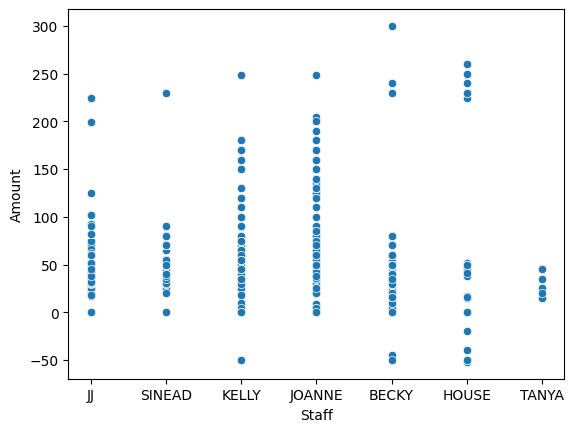

In [ ]:
df_vendas['Amount'] = np.where(
    df_vendas['Description'] == 'miscellaneous',
    df_vendas['Amount'],
    df_vendas['Amount'].abs()
)

#Nao parecem ser de estorno ou devolucao entao deixar positivo parece ser a melhor opcao
#(exceto pra miscellaneous que e sempre negativo, sera q e regra de negocio?)
sns.scatterplot(df_vendas,x='Staff',y='Amount')

<Axes: xlabel='Description', ylabel='Amount'>

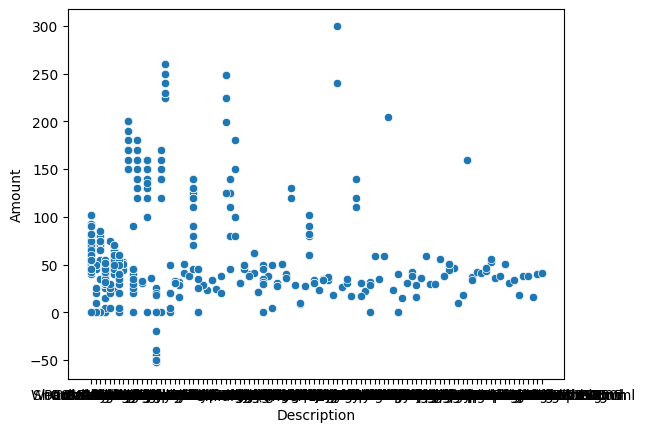

In [ ]:
sns.scatterplot(df_vendas,x='Description',y='Amount')
#Grafico de description,date, e client por Amount ficam com muitos dados no eixo X
#ai nisso o unico grafico q da pra fazer uma boa analise e o acima talvez.

In [ ]:
df_vendas_clone=df_vendas.copy()
df_vendas_clone.to_csv("vendas_limpo.csv",index=False)

In [ ]:
df_transacoes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33 entries, 0 to 32
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   IsActive  33 non-null     bool  
 1   Code      33 non-null     object
 2   Desc      32 non-null     object
 3   Cate      33 non-null     object
 4   Price     33 non-null     int64 
 5   Cost      33 non-null     int64 
dtypes: bool(1), int64(2), object(3)
memory usage: 1.5+ KB


In [ ]:
df_transacoes.duplicated().any()
#Não há linhas duplicadas.

np.False_

In [ ]:
df_transacoes.isnull().sum() #1 Descrição nula, que pode ocorrer.

,0
IsActive,0
Code,0
Desc,1
Cate,0
Price,0
Cost,0


In [ ]:
df_transacoes[df_transacoes['Desc'].isna()] #Linha está errada então podemos retirar. (Linha abaixo.)


,IsActive,Code,Desc,Cate,Price,Cost
19,True,F&F,NaN,MISC,0,0


In [ ]:
df_transacao_limpo=df_transacoes.dropna()

In [ ]:
df_transacao_limpo[df_transacao_limpo['Price'] < 0].any() #Nenhum preço negativo...

,0
IsActive,False
Code,False
Desc,False
Cate,False
Price,False
Cost,False


In [ ]:
(df_transacao_limpo==0).any().sum() #Price pode ser zero, pois não pode ser cobrado ao consumidor (como um combo, um cupom, etc.), mas cost não parece ser possível ser igual a zero.

np.int64(2)

In [ ]:
df_transacao_limpo = df_transacao_limpo[df_transacao_limpo['Cost'] != 0]
(df_transacao_limpo==0).any()

,0
IsActive,False
Code,False
Desc,False
Cate,False
Price,True
Cost,False


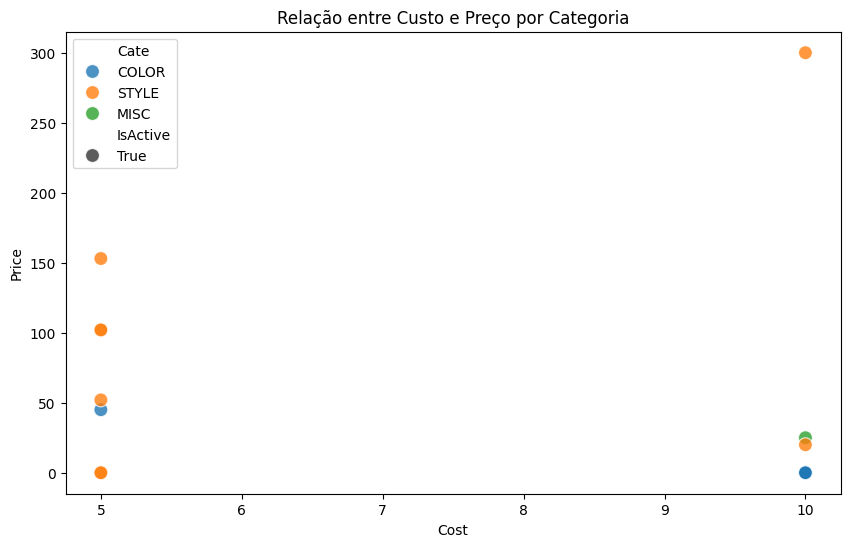

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_transacao_limpo,
    x='Cost',
    y='Price',
    hue='Cate',
    style='IsActive',
    alpha=0.8,
    s=100
)
plt.title('Relação entre Custo e Preço por Categoria')
plt.show()
#Aqui, mostra-se que a maior relação de custo por preço é STYLE, com 10 de custo e 300 de preço.

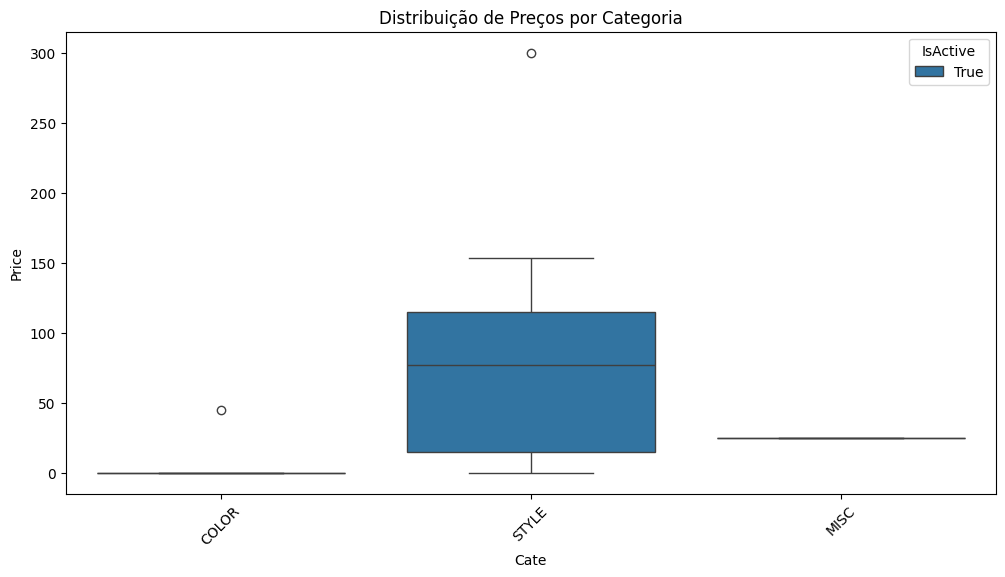

In [ ]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_transacao_limpo, x='Cate', y='Price', hue='IsActive')
plt.xticks(rotation=45)
plt.title('Distribuição de Preços por Categoria')
plt.show()
# Style, mais uma vez, apresenta os maiores preços, com um outlier de 300.

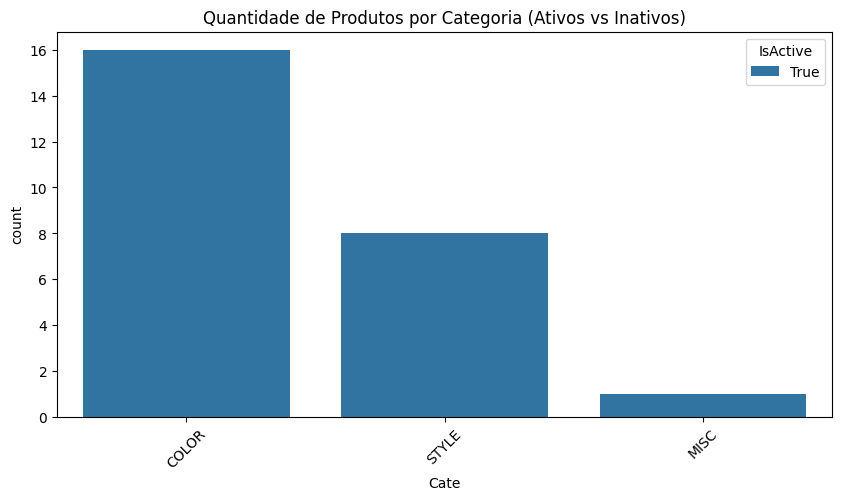

In [ ]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df_transacao_limpo, x='Cate', hue='IsActive', order=df_transacao_limpo['Cate'].value_counts().index)
plt.xticks(rotation=45)
plt.title('Quantidade de Produtos por Categoria (Ativos vs Inativos)')
plt.show()
#Contudo, a maior quantidade de produtos por categoria é COLOR ao invés de STYLE.